# Factor discovery


Review saved selections, validation summaries and figures with `REBUILD_TARGET=None`. M is the fixed manual block; T/O/L/R denote theory, OpenFE, LLM-guided and budget-matched Random-DSL factors.

Explicit reconstruction selects one target and a new `OUTPUT_DIR` under `reproductions/`; it never includes TEST. Search tools and environment setup are described in the repository README.

The 42 manual ablations fit glucose and manual features jointly with Ridge penalties {0.1, 1, 10}. The 50 factor comparisons add residual blocks to a fixed GlucoBench baseline, using 13 penalties from 0.001 to 1,000. Input representations, selection and some subject rules differ; the historical Protocol A RMSE gap of approximately 0.382 mg/dL is descriptive and cannot be attributed to residual modeling alone.

The 20-window rule fixes eligible validation subjects before factor selection (`selection_rows`); common-core refits use all core validation subjects before reporting filters (`core_rows`). Evaluation also applies the rule within each reported subset. Manual ablation did not use this selection cutoff; all subjects in both saved core TEST comparisons meet it.


In [1]:
# --- Imports, paths and optional reconstruction target ---
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from src.paths import PROJECT_ROOT

SAVED_DIR = PROJECT_ROOT / "results" / "factor_discovery"
INPUT_DIR = SAVED_DIR  # required upstream artifacts; defaults to the saved inputs
OPENFE_RANKING_DIR = INPUT_DIR / "openfe_search"  # may be a new runner output directory
OPENFE_FACTOR_DIR = INPUT_DIR  # features/values; may be a new openfe_pool output
OPENFE_SELECTION_DIR = OPENFE_FACTOR_DIR  # may be a new openfe_selection output
REBUILD_TARGET = None  # default review; choose ONE reconstruction target
OPENFE_JOBS = 16       # configurable parallelism for the separate OpenFE search
OUTPUT_DIR = None      # a NEW path under PROJECT_ROOT / "reproductions"
FACTOR_TARGETS = {"theory", "e2_e5", "e9", "t16", "openfe_inputs", "openfe_pool", "openfe_selection", "e2_o", "llm_pool", "llm_selection", "e3", "llm_description"}
PROTOCOL_A, PROTOCOL_B = "Within-subject Future Prediction", "Unseen-subject Generalization"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 16)

if REBUILD_TARGET is not None:
    if REBUILD_TARGET not in FACTOR_TARGETS | {"residuals", "primitives", "e1", "loco", "e6", "t13"}:
        raise ValueError("unknown reconstruction target")
    if OUTPUT_DIR is None:
        raise ValueError("choose a new OUTPUT_DIR under reproductions/")
    FACTOR_DIR = Path(OUTPUT_DIR).resolve()
    if not FACTOR_DIR.is_relative_to((PROJECT_ROOT / "reproductions").resolve()) or FACTOR_DIR.exists():
        raise ValueError("OUTPUT_DIR must be a new directory under reproductions/")
    FACTOR_DIR.mkdir(parents=True)
    import hashlib
    import numpy as np
    from sklearn.ensemble import HistGradientBoostingRegressor
    from src import factor_data as discovery, window_data as W, llm_results as llm_res, llm_search_cli as llm_cli
    from src.evaluation import every_fifteen_minutes, subject_ic, summarize_ic
    from src.factor_construction import absorption_id, batch2_catalog, breakfast_peak_response, conditional_lab_catalog, kernel_selection, metabolic_covariates
    from src.residuals import contrast_row, grouped_folds, oof_predictions, subject_table, time_block_folds
    from src.selection import fit_block as fit_candidates, forward_selection, redundancy_filter, selection_result
    from src.openfe_inputs import (INTERNAL_TRAIN, INTERNAL_VALIDATION, block_folds_inside, group_folds_inside, input_audit, internal_init_scores,
                                   internal_split_subjects, internal_split_time, thin_to_fifteen_minutes)
    from src.openfe_runner import evaluate_formula, formula_columns
    DATA_QUALITY_DIR, ALIGNED_DIR, WINDOWS_DIR, MANUAL_DIR = W.DATA_QUALITY_DIR, W.ALIGNED_DIR, W.WINDOWS_DIR, W.MANUAL_DIR
    WINDOW_KEY, EVENT_COLUMNS, MIN_WINDOWS = W.WINDOW_KEY, W.EVENT_COLUMNS, 20
    RULES = {"applied (>= 20 validation windows)": MIN_WINDOWS, "not applied": None}
    STAGE = "validation (optimistic: alpha and the factors were chosen on validation)"


In [2]:
# --- Scientific settings for explicit reconstruction ---
if REBUILD_TARGET is not None:
    protocol = json.loads((INPUT_DIR / "factor_protocol.json").read_text(encoding="utf-8"))


## Factor selections and validation results

T/O/L/R are selected independently on eligible validation subjects. These estimates reuse tuning/selection data and are optimistic. Native-state factors include missing indicators. L/R use matched unique-valid fitness budgets and have no formal TEST comparisons.

\[
\Delta\mathrm{RMSE}=\mathrm{RMSE}_{\mathrm{to}}-\mathrm{RMSE}_{\mathrm{from}}.
\]

Negative means lower error. Tables retain the 20-window reporting rule and 2,000 paired subject resamples (seed 42).


In [3]:
# --- Selected factors from the stored T/O/L/R selections ---
if REBUILD_TARGET is None:
    selected_rows = []
    for method in ("T", "O", "L", "R"):
        saved = pd.read_csv(SAVED_DIR / f"selection_{method}.csv")
        for row in saved.itertuples():
            members = json.loads(row.selected_set)
            expressions = members if method == "T" else json.loads(row.selected_formulas if method == "O" else row.selected_expressions)
            if not len(members) == len(expressions) == row.k_selected:
                raise ValueError(f"{method} ({row.evaluation_protocol}): selected IDs, expressions and k disagree")
            for rank, (cid, expression) in enumerate(zip(members, expressions), 1):
                selected_rows.append({"protocol": "A" if row.evaluation_protocol == PROTOCOL_A else "B", "method": method, "order": rank, "candidate_id": cid, "expression": expression})
    with pd.option_context("display.max_rows", None, "display.max_colwidth", 120):
        display(pd.DataFrame(selected_rows))


,protocol,method,order,candidate_id,expression
0,A,T,1,actstat_calories_mean_15m,actstat_calories_mean_15m
1,A,T,2,int_snack_carbs_x_native_slope_1h,int_snack_carbs_x_native_slope_1h
2,A,T,3,int_lunch_carbs_x_bmi,int_lunch_carbs_x_bmi
3,A,T,4,actstat_hr_mean_120m,actstat_hr_mean_120m
4,A,T,5,actstat_hr_max_15m,actstat_hr_max_15m
5,A,T,6,int_breakfast_carbs_x_native_slope_1h,int_breakfast_carbs_x_native_slope_1h
6,B,T,1,actstat_hr_max_15m,actstat_hr_max_15m
7,B,T,2,abs_lunch_carbs_t20_k2,abs_lunch_carbs_t20_k2
8,B,T,3,int_snack_carbs_x_native_slope_1h,int_snack_carbs_x_native_slope_1h
9,B,T,4,ratio_last_meal_carb_share,ratio_last_meal_carb_share


In [4]:
# --- Core validation contrasts (saved, optimistic tuning/selection estimates) ---
if REBUILD_TARGET is None:
    saved_mto = pd.read_csv(SAVED_DIR / "e2_O_validation.csv")
    saved_lr = pd.read_csv(SAVED_DIR / "e3_validation.csv")
    shown = pd.concat([saved_mto[saved_mto["from_config"].eq("base") & saved_mto["to_config"].isin(["base + M", "base + T", "base + O"])],
                       saved_lr[(saved_lr["from_config"].eq("base") & saved_lr["to_config"].isin(["base + L", "base + R"])) | (saved_lr["from_config"].eq("base + R") & saved_lr["to_config"].eq("base + L"))]], ignore_index=True)
    display(shown[shown["min_window_rule"].str.startswith("applied")][["evaluation_protocol", "from_config", "to_config", "subjects", "rmse_from", "rmse_to", "d_rmse", "d_rmse_low", "d_rmse_high"]].round(3))


,evaluation_protocol,from_config,to_config,subjects,rmse_from,rmse_to,d_rmse,d_rmse_low,d_rmse_high
0,Within-subject Future Prediction,base,base + M,44,11.090,10.936,-0.153,-0.265,-0.040
2,Within-subject Future Prediction,base,base + T,44,11.090,10.987,-0.103,-0.153,-0.054
4,Within-subject Future Prediction,base,base + O,44,11.090,10.903,-0.186,-0.285,-0.087
6,Unseen-subject Generalization,base,base + M,9,12.468,12.305,-0.164,-0.302,-0.018
8,Unseen-subject Generalization,base,base + T,9,12.468,12.388,-0.080,-0.136,-0.027
10,Unseen-subject Generalization,base,base + O,9,12.468,12.246,-0.222,-0.344,-0.112
12,Within-subject Future Prediction,base,base + L,44,11.090,10.977,-0.113,-0.175,-0.050
14,Within-subject Future Prediction,base,base + R,44,11.090,10.943,-0.147,-0.223,-0.069
16,Within-subject Future Prediction,base + R,base + L,44,10.943,10.977,0.034,-0.013,0.081
18,Unseen-subject Generalization,base,base + L,9,12.468,12.314,-0.155,-0.276,-0.034


In [5]:
# --- Equal unique-valid evaluation budgets from the saved search summary ---
if REBUILD_TARGET is None:
    budget = pd.read_csv(SAVED_DIR / "llm_search_summary.csv")
    if not (budget.groupby('evaluation_protocol')['fitness_evaluations'].nunique().eq(1).all()):
        raise ValueError('LLM and Random-DSL fitness budgets must match.')
    display(budget[["evaluation_protocol", "search", "model_invocations", "unique_valid_expressions", "fitness_evaluations", "pool_size", "selected_k"]])


,evaluation_protocol,search,model_invocations,unique_valid_expressions,fitness_evaluations,pool_size,selected_k
0,Within-subject Future Prediction,LLM-guided search (Claude Sonnet 5),30,67,67,25,6
1,Within-subject Future Prediction,Random-DSL,0,67,67,25,4
2,Unseen-subject Generalization,LLM-guided search (Claude Sonnet 5),30,70,70,25,5
3,Unseen-subject Generalization,Random-DSL,0,70,70,25,8


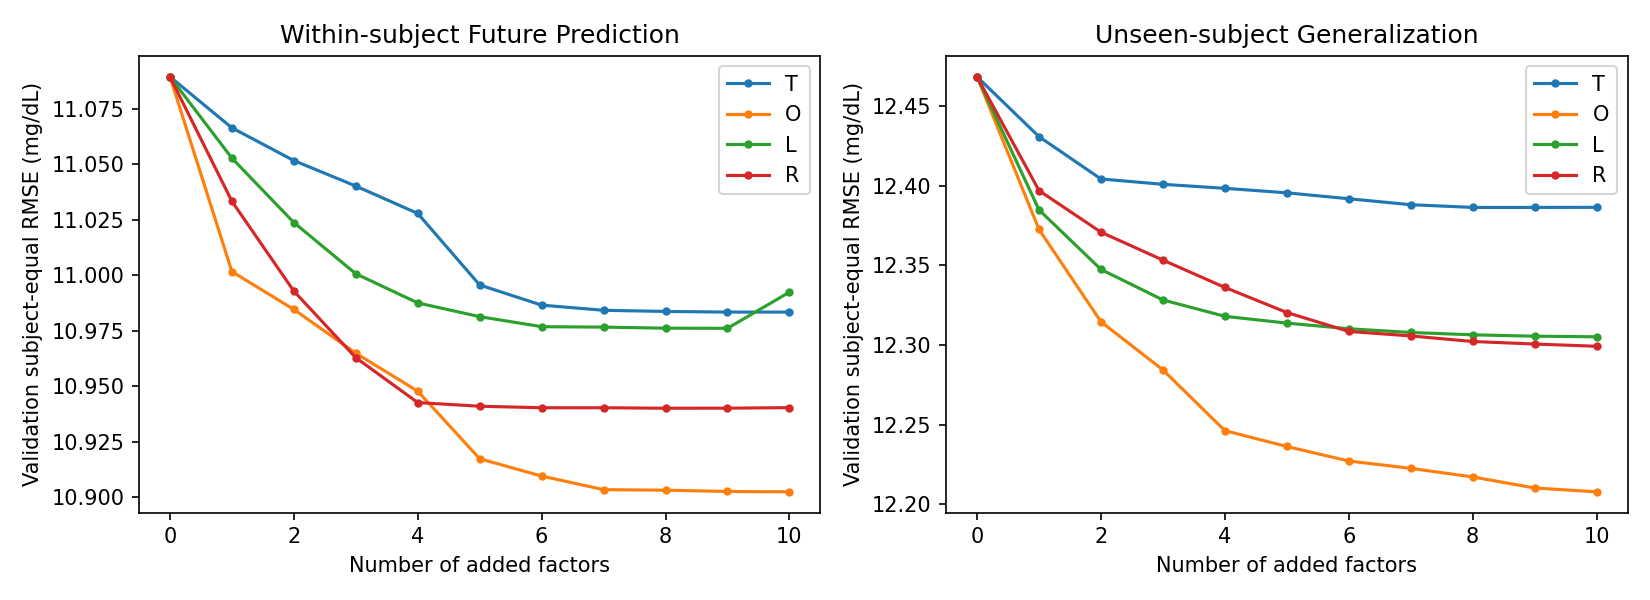

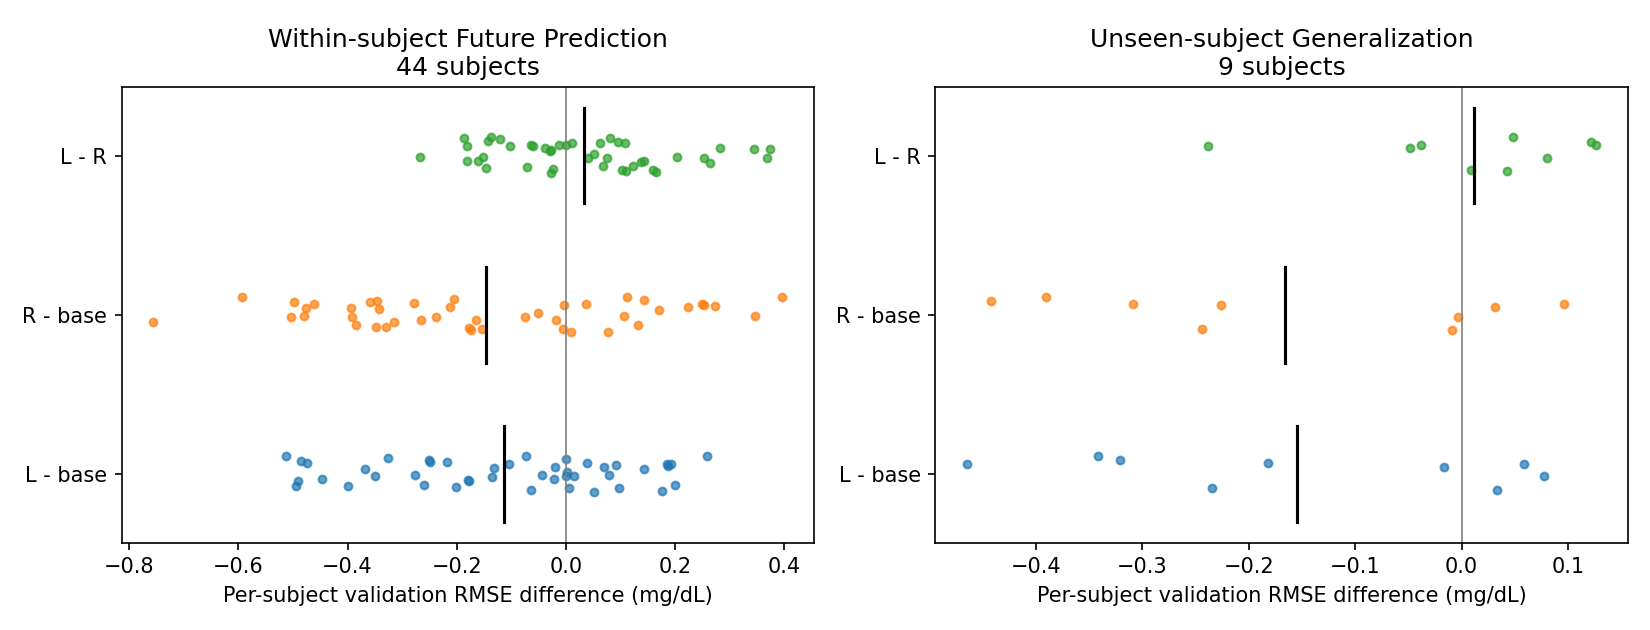

In [6]:
# Saved plots can be regenerated with the search-figures CLI from CSVs only.
if REBUILD_TARGET is None:
    for filename in ("search_validation_curves.png", "search_subject_differences.png"):
        display(Image(filename=str(PROJECT_ROOT / "figures" / filename)))


## Optional validation reconstruction

Construct candidates and validation analyses for one `REBUILD_TARGET`. Preprocessing uses TRAIN only; OOF and internal-search baselines are fitted independently within each fold. Inputs are matched by split and window key. Filtering restricts returned rows but may decode mixed-split files.


In [7]:
# --- Load factor inputs ---

if REBUILD_TARGET not in (None, "primitives"):
    context = discovery.load_context(include_factors=REBUILD_TARGET in FACTOR_TARGETS - {"theory"},
                                     include_openfe=REBUILD_TARGET in {"openfe_selection", "e2_o", "e3", "llm_description"},
                                     factor_dir=INPUT_DIR, openfe_dir=OPENFE_FACTOR_DIR, openfe_selection_dir=OPENFE_SELECTION_DIR,
                                     require_openfe_selection=REBUILD_TARGET != "openfe_selection",
        **({"load_residuals": False} if REBUILD_TARGET == "residuals" else {}))
    tables, lag_columns = context["tables"], context["lag_columns"]
    G_FEATURES, FEATURE_GROUPS, MANUAL = context["G_FEATURES"], context["FEATURE_GROUPS"], context["MANUAL"]
    get_inputs, generate_matrix, BMI = context["get_inputs"], context["generate_matrix"], context["BMI"]
    catalog_batch1 = context["catalog_batch1"]
    if REBUILD_TARGET in FACTOR_TARGETS - {"theory"}:
        catalog, T_K = context["catalog"], context["T_K"]
        # Keep batch 1 / native indicator / batch 2 column order.
        MODEL_TABLES = {}
        for name, table in context["MODEL_TABLES"].items():
            columns = list(table.columns)
            columns.remove("native_missing")
            columns.insert(len(tables[name].columns) + len(catalog_batch1), "native_missing")
            MODEL_TABLES[name] = table[columns]
        if "O_TABLES" in context:
            O_TABLES = {name: table[list(MODEL_TABLES[name]) + [c for c in table if c not in MODEL_TABLES[name]]]
                        for name, table in context["O_TABLES"].items()}
            O_K, o_model_columns = context["O_K"], context["o_model_columns"]
            openfe_features, FORMULA_OF = context["openfe_features"], context["FORMULA_OF"]


### Baseline and OOF residuals

Residual augmentation uses \(\hat y=\hat y_{\mathrm{base}}+\hat r\). A uses five non-forward temporal blocks with complete-support edge exclusion; B uses five subject folds. Validation uses the baseline fitted on all TRAIN rows. OOF fits remain independent, with missingness and time boundaries preserved.


In [8]:
# --- Out-of-fold training residuals (OOF residual design B) ---

if REBUILD_TARGET == "residuals":
    RESIDUAL_PATH = FACTOR_DIR / "base_residuals.parquet"
    split_scope = pd.read_csv(DATA_QUALITY_DIR / "split_scope_v1.csv", parse_dates=["start_time", "protocol_a_train_end_time"]).set_index("subject_id")
    bounds = pd.DataFrame({"lo": split_scope["start_time"], "hi": split_scope["protocol_a_train_end_time"]})
    frames = []
    for name, table in tables.items():
        train = table[table["split"].eq("train")]
        fold = time_block_folds(train, bounds) if name == PROTOCOL_A else grouped_folds(train["subject"])
        if name == PROTOCOL_B:
            members = {f"fold_{k}": sorted(int(s) for s in train.loc[fold == k, "subject"].unique()) for k in range(5)}
            if not (members == protocol['oof_specification']['protocol_B']['fold_membership_subjects']):
                raise ValueError('OOF subject membership differs from the configured folds.')
        oof = oof_predictions(train, fold, lag_columns[name])
        frame = table[["subject", "origin_time", "task_id", "split", "target_value", "base_prediction"]].copy()
        frame.insert(0, "evaluation_protocol", name)
        frame["oof_fold"] = pd.array([pd.NA] * len(frame), dtype="Int8")
        frame.loc[train.index, "oof_fold"] = fold
        frame["oof_prediction"] = np.nan
        frame.loc[train.index, "oof_prediction"] = oof
        frame["residual_in_sample"] = frame["target_value"] - frame["base_prediction"]
        frame["residual"] = np.where(frame["split"].eq("train"), frame["target_value"] - frame["oof_prediction"], frame["residual_in_sample"])
        frames.append(frame)
    pd.concat(frames, ignore_index=True).to_parquet(RESIDUAL_PATH, index=False)


### E1: feature-group residual blocks

Evaluate the seven registered group contrasts on identical core TRAIN/VALIDATION windows. `e1_validation.csv` retains both the >=20-validation-window rule and the version without that rule; these are residual-block fits, not joint refits of the glucose baseline.


In [9]:
# --- E1: seven contrasts per protocol on the core cohort ---

if REBUILD_TARGET not in (None, "primitives"):
    def block_columns(groups):
        return [c for g in groups if g != "G" for c in FEATURE_GROUPS[g]]


    def fit_block(table, columns, cohort="cohort_core", identity_proxy=False):
        part = table[table[cohort]]
        train = part[part["split"].eq("train") & part["residual"].notna()]
        valid = part[part["split"].eq("validation")]
        if identity_proxy:
            proxy = train.groupby("subject")["residual"].mean()
            train, valid = train.assign(identity_proxy=train["subject"].map(proxy)), valid.assign(identity_proxy=valid["subject"].map(proxy))
            columns = [*columns, "identity_proxy"]
        return fit_candidates(train, valid, columns)

    if REBUILD_TARGET == "e1":
        ablation = pd.read_csv(MANUAL_DIR / "ablation_matrix.csv")
        CONFIGS = ablation.query("record_type == 'configuration'").set_index("config_id")["feature_groups"].str.split("+").to_dict()
        CONTRASTS = ablation.query("record_type == 'contrast'")[["config_id", "from_config", "to_config", "group_tested", "contrast_type"]]
        e1_rows = []
        for name, table in tables.items():
            fits = {config: fit_block(table, block_columns(groups)) for config, groups in CONFIGS.items()}
            for c in CONTRASTS.itertuples(index=False):
                (alpha_from, rows_from, _), (alpha_to, rows_to, n_train) = fits[c.from_config], fits[c.to_config]
                for rule, minimum in RULES.items():
                    e1_rows.append({"evaluation_protocol": name, "contrast_id": c.config_id, "from_config": c.from_config, "to_config": c.to_config, "group_tested": c.group_tested,
                                    "contrast_type": c.contrast_type, "cohort": "cohort_core", "min_window_rule": rule, "alpha_from": alpha_from, "alpha_to": alpha_to,
                                    "training_windows": n_train, **contrast_row(rows_from, rows_to, minimum), "stage": "validation (optimistic: alpha chosen on validation)"})
        pd.DataFrame(e1_rows).to_csv(FACTOR_DIR / "e1_validation.csv", index=False)


### Single-feature checks

For each M50 feature, compare drop-one with `base + M` and add-one with `base`. Positive drop-one Delta RMSE and negative add-one Delta RMSE indicate lower error when the feature is present. Each fit selects its own alpha; outputs are in `loco_validation.csv`.


In [10]:
# --- LOCO: drop-one against base + M, add-one against the base ---

if REBUILD_TARGET == 'loco':
    LOCO_PATH = FACTOR_DIR / "loco_validation.csv"
    GROUP_OF = {c: g for g in ("A", "D", "B") for c in FEATURE_GROUPS[g]}
    loco_rows = []
    for name, table in tables.items():
        full = fit_block(table, MANUAL)
        base_only = fit_block(table, [])
        for feature in MANUAL:
            drop = fit_block(table, [c for c in MANUAL if c != feature])
            add = fit_block(table, [feature])
            for mode, (rows_from, rows_to), (alpha, n_train) in (("drop_one (vs base + M)", (full[1], drop[1]), (drop[0], drop[2])),
                                                                 ("add_one (vs base)", (base_only[1], add[1]), (add[0], add[2]))):
                for rule, minimum in RULES.items():
                    loco_rows.append({"evaluation_protocol": name, "mode": mode, "feature": feature, "group": GROUP_OF[feature], "min_window_rule": rule, "alpha": alpha,
                                      "training_windows": n_train, **contrast_row(rows_from, rows_to, minimum)})
    pd.DataFrame(loco_rows).to_csv(LOCO_PATH, index=False)


### E6: TRAIN identity proxy (protocol A)

Append each subject's mean OOF TRAIN residual to both sides of the static, laboratory or Gut contrast. VALIDATION reuses that value unchanged; no validation residual estimates the proxy. The TRAIN mean includes each window's own OOF residual and is not a causal control. Laboratory/Gut contexts are offline checks. B has no corresponding proxy for unseen validation subjects. Reconstruction saves `e6_validation.csv`.


In [11]:
# --- E6: increments of B, offline laboratory and Gut variables without and with the identity proxy (Protocol A) ---

if REBUILD_TARGET == 'e6':
    E6_CONTEXTS = [("core static features alone", "cohort_core", [], ["B"], "main"), ("core static features after activity and diet", "cohort_core", ["A", "D"], ["B"], "main"),
                   ("offline laboratory values", "cohort_core", ["A", "D", "B"], ["B_lab"], "offline sensitivity (not in the main predictor space)"),
                   ("Gut scores, ordinal", "cohort_gut", ["A", "D", "B"], ["Gut_ordinal"], "optional"), ("Gut scores, categorical", "cohort_gut", ["A", "D", "B"], ["Gut_categorical"], "optional")]
    E6_PATH = FACTOR_DIR / "e6_validation.csv"
    e6_rows = []
    table = tables[PROTOCOL_A]
    for context, cohort, reference, added, role in E6_CONTEXTS:
        for proxy in (False, True):
            rows_from = fit_block(table, block_columns(reference), cohort, proxy)
            rows_to = fit_block(table, block_columns([*reference, *added]), cohort, proxy)
            for rule, minimum in RULES.items():
                e6_rows.append({"evaluation_protocol": PROTOCOL_A, "context": context, "added_block": "+".join(added), "analysis_role": role, "cohort": cohort, "identity_proxy": proxy,
                                "min_window_rule": rule, "alpha_from": rows_from[0], "alpha_to": rows_to[0], "training_windows": rows_to[2], **contrast_row(rows_from[1], rows_to[1], minimum),
                                "stage": "validation (optimistic: alpha chosen on validation)"})
    pd.DataFrame(e6_rows).to_csv(E6_PATH, index=False)


### GBT target-form check

Use the baseline shallow GBT grid on the ten registered glucose features to compare the absolute target with \(y-g(t)\), added back at prediction. Choose 100 or 300 iterations on VALIDATION without early stopping; save `gbt_target_validation.csv`.


In [12]:
# --- T13: absolute target against change target ---

if REBUILD_TARGET == "t13":
    GBT_PATH = FACTOR_DIR / "gbt_target_validation.csv"
    gbt_rows, fitted = [], {}
    for name, table in tables.items():
        train, valid = table[table["split"].eq("train")], table[table["split"].eq("validation")]
        for form in ("absolute y", "change y - g(t)"):
            offset = 0.0 if form == "absolute y" else 1.0
            for max_iter in (100, 300):
                config = f"max_iter={max_iter},max_depth=3,learning_rate=0.1"
                model = HistGradientBoostingRegressor(max_iter=max_iter, max_depth=3, learning_rate=0.1, early_stopping=False, random_state=0)
                model.fit(train[G_FEATURES], train["target_value"] - offset * train["glucose_lag_0min"])
                for split, part in (("train", train), ("validation", valid)):
                    prediction = model.predict(part[G_FEATURES]) + offset * part["glucose_lag_0min"].to_numpy()
                    fitted[(name, form, max_iter, split)] = subject_table(part["subject"].to_numpy(), prediction - part["target_value"].to_numpy())
                    gbt_rows.append({"record_type": "fit", "evaluation_protocol": name, "target_form": form, "max_iter": max_iter, "split": split, "windows": len(part), "subjects": part["subject"].nunique(),
                                     "subject_mean_rmse": fitted[(name, form, max_iter, split)]["rmse"].mean(), "pooled_rmse": float(np.sqrt(np.mean((prediction - part["target_value"].to_numpy()) ** 2)))})
        fits = pd.DataFrame([r for r in gbt_rows if r["evaluation_protocol"] == name and r["split"] == "validation"])
        chosen = {form: int(fits.loc[fits["target_form"].eq(form)].sort_values("subject_mean_rmse").iloc[0]["max_iter"]) for form in fits["target_form"].unique()}
        for row in gbt_rows:
            if row["evaluation_protocol"] == name:
                row["selected"] = chosen[row["target_form"]] == row["max_iter"]
        for rule, minimum in RULES.items():
            gbt_rows.append({"record_type": "contrast (change minus absolute, selected fits)", "evaluation_protocol": name, "target_form": "change y - g(t) vs absolute y", "split": "validation",
                             "min_window_rule": rule, **contrast_row(fitted[(name, "absolute y", chosen["absolute y"], "validation")], fitted[(name, "change y - g(t)", chosen["change y - g(t)"], "validation")], minimum)})
    pd.DataFrame(gbt_rows).to_csv(GBT_PATH, index=False)


### Window primitives

The shared `window_data` loaders enforce admitted keys; `factor_construction` implements availability-constrained operators and native state.


In [13]:
# --- Window-level primitives of each protocol ---

if REBUILD_TARGET == "primitives" or REBUILD_TARGET in FACTOR_TARGETS:
    if REBUILD_TARGET == "primitives":
        for tag, name in (("A", PROTOCOL_A), ("B", PROTOCOL_B)):
            keys = W.load_keys(name, W.PRE_LOCK_SPLITS)[WINDOW_KEY + ["split"]]
            minutes, events = W.load_inputs(keys, W.PRE_LOCK_SPLITS)
            W.primitives_table(keys, minutes, events).to_parquet(FACTOR_DIR / f"primitives_{tag}.parquet", index=False)
        static = pd.read_parquet(ALIGNED_DIR / "static_canonical.parquet", columns=["subject", "bio__bmi", "bio__hba1c_lab_raw", "bio__fasting_glucose_lab_mg_dl", "bio__fasting_insulin_raw"])
        group = pd.read_csv(DATA_QUALITY_DIR / "split_scope_v1.csv").set_index("subject_id")["protocol_b_group"].rename("protocol_B_group")
        metabolic_covariates(static).merge(group, left_on="subject", right_index=True, validate="one_to_one").to_csv(FACTOR_DIR / "metabolic_covariates.csv", index=False)
    elif REBUILD_TARGET in {"theory", "openfe_inputs", "openfe_pool"}:
        primitives = {name: pd.read_parquet(INPUT_DIR / f"primitives_{tag}.parquet") for tag, name in (("A", PROTOCOL_A), ("B", PROTOCOL_B))}


### Candidate catalog and batches

The main grid contains 206 candidates: 160 absorption kernels, six nutrient ratios, 24 activity terms, four native-state terms and 12 meal-by-baseline-state interactions. Batch 1 has 187 recipes; batch 2 adds 19 using TRAIN-selected kernels.

`generator` and `generator_params` record dependencies and formulas. Native-state terms retain missing indicators. Twelve laboratory interactions form a separate sensitivity analysis (E11), not the main candidate pool.


In [14]:
# --- Catalog of the candidate families and the inputs of each protocol ---

if REBUILD_TARGET == "theory":
    catalog_lab = conditional_lab_catalog()
    frames = []
    for name in (PROTOCOL_A, PROTOCOL_B):
        frame = generate_matrix(name, catalog_batch1, get_inputs(name))
        frame.insert(0, "evaluation_protocol", name)
        frames.append(frame)
    batch1 = pd.concat(frames, ignore_index=True)
    batch1.to_parquet(FACTOR_DIR / "candidates_batch1.parquet", index=False)


## TRAIN IC ranking

Use core TRAIN windows with OOF residuals, thinned to 15-minute steps. Rank each candidate by the absolute mean of subject-level Spearman ICs; retain signed means and same-sign shares. A subject needs three defined, nonconstant pairs. Descriptive t/Wilcoxon/BY values do not decide inclusion.

Choose each nutrient/meal kernel by its largest absolute mean TRAIN IC, then build batch 2. Save kernel choices, candidate/subject ICs and the top five candidates per family.


In [15]:
# --- Training windows with candidates attached; IC of batch 1 and the selected kernels ---

if REBUILD_TARGET == "theory":
    native_flag = pd.concat([frame[[*WINDOW_KEY, "split", "native_missing"]] for frame in primitives.values()]).drop_duplicates([*WINDOW_KEY, "split"])
    MODEL_TABLES = {}
    for name in (PROTOCOL_A, PROTOCOL_B):
        part = batch1[batch1["evaluation_protocol"].eq(name)].drop(columns="evaluation_protocol")
        MODEL_TABLES[name] = (tables[name].merge(part, on=[*WINDOW_KEY, "split"], validate="one_to_one")
                              .merge(native_flag, on=[*WINDOW_KEY, "split"], validate="one_to_one"))


    def screening_rows(name, columns):
        """Subject-level IC table of `columns` on the thinned core training windows of one protocol."""
        table = MODEL_TABLES[name]
        train = table[table["split"].eq("train")]
        first = train.groupby("subject")["origin_time"].min()
        core = train[train["cohort_core"] & train["residual"].notna()]
        return subject_ic(core[every_fifteen_minutes(core, first)], columns)



    ic1, counts1, summaries1, tau_star, catalog_batch2 = {}, {}, {}, {}, {}
    for name in (PROTOCOL_A, PROTOCOL_B):
        ic1[name], counts1[name] = screening_rows(name, list(catalog_batch1["candidate_id"]))
        summary = summarize_ic(ic1[name]).merge(catalog_batch1[["candidate_id", "family", "parameters", "generator_params"]], on="candidate_id")
        summaries1[name] = summary
        tau_star[name] = kernel_selection(summary)
        catalog_batch2[name] = batch2_catalog(tau_star[name], name)
    tau_rows = []
    for name in (PROTOCOL_A, PROTOCOL_B):
        summary = summaries1[name].set_index("candidate_id")
        for (nutrient, meal_class), (tau, k) in tau_star[name].items():
            row = summary.loc[absorption_id(meal_class, nutrient, tau, k)]
            tau_rows.append({"evaluation_protocol": name, "nutrient": nutrient, "meal_class": meal_class, "tau": tau, "k": k, "mean_ic": row["mean_ic"], "abs_mean_ic": row["abs_mean_ic"],
                             "same_sign_share": row["same_sign_share"], "subjects_with_ic": row["subjects_with_ic"]})
    tau_star_table = pd.DataFrame(tau_rows)
    tau_star_table.to_csv(FACTOR_DIR / "tau_star_selection.csv", index=False)

    frames = []
    for name in (PROTOCOL_A, PROTOCOL_B):
        both = pd.concat([catalog_batch1, catalog_batch2[name]], ignore_index=True)
        if not both["candidate_id"].is_unique or not len(both) == protocol["candidate_families"]["planned_size_main"] <= protocol["candidate_families"]["total_cap"]:
            raise ValueError("candidate pool must match the configured size, cap and unique IDs")
        frame = generate_matrix(name, both, get_inputs(name), wanted=list(catalog_batch2[name]["candidate_id"]))
        frame.insert(0, "evaluation_protocol", name)
        frames.append(frame)
    batch2 = pd.concat(frames, ignore_index=True)
    batch2.to_parquet(FACTOR_DIR / "candidates_batch2.parquet", index=False)
    catalog = pd.concat([catalog_batch1, catalog_batch2[PROTOCOL_A], catalog_batch2[PROTOCOL_B], catalog_lab], ignore_index=True)
    catalog.to_csv(FACTOR_DIR / "candidate_catalog.csv", index=False)
    for name in (PROTOCOL_A, PROTOCOL_B):
        part = batch2[batch2["evaluation_protocol"].eq(name)].drop(columns="evaluation_protocol")
        MODEL_TABLES[name] = MODEL_TABLES[name].merge(part, on=[*WINDOW_KEY, "split"], validate="one_to_one")


In [16]:
# --- IC of all 206 main candidates, kernel-by-kernel records and the K = 5 per family ---

if REBUILD_TARGET == "theory":
    K_PER_FAMILY = protocol["screening"]["keep_per_family"]["K"]
    main = catalog[~catalog["family"].eq("meal_x_lab_state_conditional")]
    summaries, subject_rows = [], []
    for name in (PROTOCOL_A, PROTOCOL_B):
        recipes = main[main["evaluation_protocol"].isin(["both", name])]
        ids2 = list(catalog_batch2[name]["candidate_id"])
        ic2, counts2 = screening_rows(name, ids2)
        ic = pd.concat([ic1[name], ic2], axis=1)[list(recipes["candidate_id"])]
        counts = pd.concat([counts1[name], counts2], axis=1)[list(recipes["candidate_id"])]
        summary = summarize_ic(ic).merge(recipes[["candidate_id", "batch", "family"]], on="candidate_id")
        summary["rank_in_family"] = summary.groupby("family")["abs_mean_ic"].rank(ascending=False, method="first", na_option="bottom").astype(int)
        summary["kept_top_k"] = summary["rank_in_family"] <= K_PER_FAMILY
        summary.insert(0, "evaluation_protocol", name)
        summaries.append(summary)
        long = ic.stack(future_stack=True).rename("ic").reset_index().rename(columns={"level_1": "candidate_id"})
        long["windows"] = counts.stack().to_numpy()
        long.insert(0, "evaluation_protocol", name)
        subject_rows.append(long)
    screening = pd.concat(summaries, ignore_index=True)
    screening.to_csv(FACTOR_DIR / "screening_results.csv", index=False)
    pd.concat(subject_rows, ignore_index=True).to_csv(FACTOR_DIR / "screening_subject_ic.csv", index=False)


## Redundancy filtering and selection

Greedily remove candidates with TRAIN Spearman correlation \(\lvert\rho\rvert>0.9\) against a baseline lag or a retained candidate. Forward selection minimizes validation subject-equal RMSE, tuning Ridge separately for each candidate block, up to ten factors.

Choose the smallest set whose mean subject-paired RMSE difference from the best path point does not exceed its standard error. `selection_rows` fixes subjects with at least 20 core validation windows before selection and penalty tuning; `core_rows` includes all core validation subjects before reporting filters.


In [17]:
# --- Redundancy filter on the training windows ---

if REBUILD_TARGET in FACTOR_TARGETS:
    RHO_THRESHOLD = 0.9
    if REBUILD_TARGET == "theory":
        records = []
        for name in (PROTOCOL_A, PROTOCOL_B):
            table = MODEL_TABLES[name]
            train = table[table["split"].eq("train")]
            first = train.groupby("subject")["origin_time"].min()
            core = train[train["cohort_core"] & train["residual"].notna()]
            thinned = core[every_fifteen_minutes(core, first)]
            pool = screening[screening["evaluation_protocol"].eq(name) & screening["kept_top_k"]].sort_values("abs_mean_ic", ascending=False)
            order = list(pool["candidate_id"])
            by_method = {m: redundancy_filter(order, thinned[order], thinned[lag_columns[name]], RHO_THRESHOLD, m) for m in ("spearman", "pearson")}
            record = by_method["spearman"].merge(by_method["pearson"][["candidate_id", "decision"]].rename(columns={"decision": "decision_if_pearson"}), on="candidate_id")
            record = record.merge(pool[["candidate_id", "family", "mean_ic", "abs_mean_ic"]], on="candidate_id")
            record.insert(0, "evaluation_protocol", name)
            records.append(record)
        redundancy = pd.concat(records, ignore_index=True)
        redundancy.to_csv(FACTOR_DIR / "redundancy_filter.csv", index=False)


In [18]:
# --- Validation forward selection and the one-standard-error choice ---

if REBUILD_TARGET in FACTOR_TARGETS:
    NATIVE_IDS = set(catalog.loc[catalog["uses_native_state"], "candidate_id"])

    def model_columns(selected):
        return list(selected) + (["native_missing"] if NATIVE_IDS & set(selected) else [])

    def core_rows(name, table=None):
        table = MODEL_TABLES[name] if table is None else table
        return table[table["split"].eq("train") & table["cohort_core"] & table["residual"].notna()], table[table["split"].eq("validation") & table["cohort_core"]]


    def selection_rows(name, table=None):
        """Fix eligible validation subjects BEFORE selection, unlike core_rows."""
        train, valid = core_rows(name, table)
        return train, valid[valid.groupby("subject")["subject"].transform("size") >= MIN_WINDOWS]


    if REBUILD_TARGET == "theory":
        curves, chosen = [], []
        for name in (PROTOCOL_A, PROTOCOL_B):
            train, valid = selection_rows(name)
            pool = list(redundancy[redundancy["evaluation_protocol"].eq(name) & redundancy["decision"].eq("kept")]["candidate_id"])
            curve, by_k = forward_selection(train, valid, pool, model_columns, k_max=protocol["selection"]["k_max"])
            curve, row = selection_result(curve, by_k, name, train, valid, include_unpaired=True, pool_size=len(pool))
            curves.append(curve)
            chosen.append(row)
        curves, selection = pd.concat(curves, ignore_index=True), pd.DataFrame(chosen)
        curves.to_csv(FACTOR_DIR / "validation_curves_T.csv", index=False)
        selection.to_csv(FACTOR_DIR / "selection_T.csv", index=False)
        T_K = {row.evaluation_protocol: json.loads(row.selected_set) for row in selection.itertuples()}


### E5/E2: family removal and block combinations

E5 refits \(T_k\) after removing one represented family; positive reduced-minus-full Delta RMSE means removal raised error. E2 compares the baseline, M, \(T_k\) and M+\(T_k\) on common core windows. Neither analysis reselects factors; both retain the two reporting minimum-window rules.


In [19]:
# --- E5 family ablation and E2 combinations ---

if REBUILD_TARGET == "e2_e5":
    E5_PATH, E2_PATH = FACTOR_DIR / "e5_validation.csv", FACTOR_DIR / "e2_validation.csv"
    FAMILY_OF = catalog.drop_duplicates("candidate_id").set_index("candidate_id")["family"]
    FAMILY_ORDER = ["meal_absorption", "nutrient_ratios", "activity_kernels", "meal_x_baseline_state", "native_glucose_state"]
    e5_rows, e2_rows = [], []
    for name in (PROTOCOL_A, PROTOCOL_B):
        train, valid = core_rows(name)
        selected = T_K[name]
        full = fit_candidates(train, valid, model_columns(selected))
        for family in [f for f in FAMILY_ORDER if any(FAMILY_OF[c] == f for c in selected)]:
            rest = [c for c in selected if FAMILY_OF[c] != family]
            reduced = fit_candidates(train, valid, model_columns(rest))
            for rule, minimum in RULES.items():
                e5_rows.append({"evaluation_protocol": name, "family_removed": family, "factors_removed": json.dumps([c for c in selected if FAMILY_OF[c] == family]), "k_full": len(selected),
                                "k_reduced": len(rest), "alpha_full": full[0], "alpha_reduced": reduced[0], "min_window_rule": rule, "training_windows": full[2],
                                **contrast_row(full[1], reduced[1], minimum), "stage": STAGE})
        configs = {"base": [], "base + M": MANUAL, "base + T": model_columns(selected), "base + M + T": MANUAL + model_columns(selected)}
        fits = {config: full if config == "base + T" else fit_candidates(train, valid, columns) for config, columns in configs.items()}
        if not (len({tuple(f[1].index) for f in fits.values()}) == 1 and len({int(f[1]['n_windows'].sum()) for f in fits.values()}) == 1):
            raise ValueError('Models must use identical paired subjects and window counts.')
        for source, target in (("base", "base + M"), ("base", "base + T"), ("base + M", "base + M + T"), ("base + T", "base + M + T")):
            for rule, minimum in RULES.items():
                e2_rows.append({"evaluation_protocol": name, "from_config": source, "to_config": target, "k_T": len(selected), "min_window_rule": rule, "alpha_from": fits[source][0],
                                "alpha_to": fits[target][0], "training_windows": fits[target][2], **contrast_row(fits[source][1], fits[target][1], minimum), "stage": STAGE})
    pd.DataFrame(e5_rows).to_csv(E5_PATH, index=False)
    pd.DataFrame(e2_rows).to_csv(E2_PATH, index=False)


### E9: delayed-meal inputs

Keep the selected factors and TRAIN-selected kernels. Recompute diet and meal-dependent T inputs for logged time, dinner/snack delayed 30 minutes, and all meals delayed 30 minutes; other inputs stay unchanged.

**Implementation:** original log times remain event times. Events younger than the delay are unavailable, and early gamma weights are zeroed without renormalization. Each setting refits its TRAIN imputer, scaler and Ridge coefficients and selects alpha on VALIDATION. `same model, delayed minus logged` means the same factor set refitted per setting, not a fixed-fit perturbation. Reconstruction saves `e9_validation.csv`.


In [20]:
# --- E9: base + M and base + T_k with the meal inputs recomputed under three availability settings ---

if REBUILD_TARGET == "e9":
    E9_PATH = FACTOR_DIR / "e9_validation.csv"
    SETTINGS = {"logged time": "logged", "Dinner and Snack delayed 30 minutes": "delay_free", "all meals delayed 30 minutes": "delay_all"}
    D_COLUMNS = FEATURE_GROUPS["D"]


    def setting_table(name, version):
        table = MODEL_TABLES[name]
        own = catalog[catalog["evaluation_protocol"].isin(["both", name]) & catalog["generation_status"].eq("generated")]
        keys, minutes, events = get_inputs(name)
        diet = W.diet_matrix(keys, minutes, events, D_COLUMNS, version)[WINDOW_KEY + ["split"] + D_COLUMNS]
        factors = generate_matrix(name, own, (keys, minutes, events), version, wanted=T_K[name])[WINDOW_KEY + ["split"] + T_K[name]]
        return table.drop(columns=D_COLUMNS + T_K[name]).merge(diet, on=WINDOW_KEY + ["split"], validate="one_to_one").merge(factors, on=WINDOW_KEY + ["split"], validate="one_to_one")
    e9_rows, e9_fits = [], {}
    for name in (PROTOCOL_A, PROTOCOL_B):
        for setting, version in SETTINGS.items():
            table = setting_table(name, version)
            if version == "logged":
                reference = MODEL_TABLES[name]
                merged = table.merge(reference[WINDOW_KEY + ["split"] + D_COLUMNS + T_K[name]], on=WINDOW_KEY + ["split"], suffixes=("", "_stored"))
                if not (all((np.allclose(merged[c], merged[c + '_stored'], rtol=0, atol=1e-09, equal_nan=True) for c in D_COLUMNS + T_K[name]))):
                    raise ValueError('Logged meal features differ from the materialized reference.')
            train = table[table["split"].eq("train") & table["cohort_core"] & table["residual"].notna()]
            valid = table[table["split"].eq("validation") & table["cohort_core"]]
            e9_fits[(name, setting)] = {"base": fit_candidates(train, valid, []) if version == "logged" else e9_fits[(name, "logged time")]["base"], "base + M": fit_candidates(train, valid, MANUAL),
                                        "base + T": fit_candidates(train, valid, model_columns(T_K[name]))}
        for setting in SETTINGS:
            for model in ("base + M", "base + T"):
                for rule, minimum in RULES.items():
                    fit, base = e9_fits[(name, setting)][model], e9_fits[(name, setting)]["base"]
                    logged = e9_fits[(name, "logged time")][model]
                    e9_rows.append({"record_type": "gain over the base", "evaluation_protocol": name, "setting": setting, "meal_version": SETTINGS[setting], "model": model, "min_window_rule": rule,
                                    "alpha": fit[0], "training_windows": fit[2], **contrast_row(base[1], fit[1], minimum), "stage": STAGE})
                    if setting != "logged time":
                        e9_rows.append({"record_type": "same model, delayed minus logged", "evaluation_protocol": name, "setting": setting, "meal_version": SETTINGS[setting], "model": model,
                                        "min_window_rule": rule, "alpha": fit[0], "training_windows": fit[2], **contrast_row(logged[1], fit[1], minimum), "stage": STAGE})
    pd.DataFrame(e9_rows).to_csv(E9_PATH, index=False)


### Individual breakfast response (protocol A)

Estimate a subject's median peak glucose increment per carbohydrate gram from at least three breakfasts whose entire 180-minute response lies in TRAIN. Missing parameters use TRAIN median imputation. Multiply this fixed subject parameter by the TRAIN-selected breakfast kernel, then compare kernel and interaction blocks on VALIDATION. TRAIN glucose contributes to the parameter; this is an offline proxy. B's unseen subjects have no TRAIN breakfast response.


In [21]:
# --- T16: subject-specific peak increment per gram of carbohydrate from the training-period breakfasts ---

if REBUILD_TARGET == 't16':
    T16_PATH = FACTOR_DIR / "t16_validation.csv"
    RESPONSE_HORIZON, MIN_BREAKFASTS = 180, 3
    tau_star_table = pd.read_csv(INPUT_DIR / "tau_star_selection.csv")
    keys, minutes, events = get_inputs(PROTOCOL_A)
    train_end = pd.read_csv(DATA_QUALITY_DIR / "split_scope_v1.csv", parse_dates=["protocol_a_train_end_time"]).set_index("subject_id")["protocol_a_train_end_time"]
    empty_events = pd.DataFrame({"timestamp": pd.to_datetime([]), **{c: [] for c in EVENT_COLUMNS}})
    responses = []
    for subject, frame in minutes.items():
        response = breakfast_peak_response(frame["libre_gl"].to_numpy(float), frame["timestamp"], events.get(subject, empty_events), train_end[subject], RESPONSE_HORIZON)
        responses.append(response.assign(subject=subject))
    responses = pd.concat(responses, ignore_index=True)
    theta = responses.groupby("subject")["per_gram"].agg(["median", "size"])
    theta["parameter"] = theta["median"].where(theta["size"] >= MIN_BREAKFASTS)
    theta = theta.reindex(sorted(minutes)).fillna({"size": 0})
    kernel_row = tau_star_table[tau_star_table["evaluation_protocol"].eq(PROTOCOL_A) & tau_star_table["nutrient"].eq("carbs") & tau_star_table["meal_class"].eq("breakfast")].iloc[0]
    kernel_id = absorption_id("breakfast", "carbs", int(kernel_row["tau"]), int(kernel_row["k"]))
    table = MODEL_TABLES[PROTOCOL_A].assign(theta=lambda d: d["subject"].map(theta["parameter"]))
    table["t16_theta_x_kernel"] = table["theta"] * table[kernel_id]
    train = table[table["split"].eq("train") & table["cohort_core"] & table["residual"].notna()]
    valid = table[table["split"].eq("validation") & table["cohort_core"]]
    fits = {
        "base": fit_candidates(train, valid, []),
        "kernel": fit_candidates(train, valid, [kernel_id]),
        "kernel + interaction": fit_candidates(train, valid, [kernel_id, "t16_theta_x_kernel"])
    }
    t16_rows = []
    for source, target in (("base", "kernel"), ("base", "kernel + interaction"), ("kernel", "kernel + interaction")):
        for rule, minimum in RULES.items():
            t16_rows.append({"record_type": "contrast", "evaluation_protocol": PROTOCOL_A, "from_config": source, "to_config": target, "kernel": kernel_id, "min_window_rule": rule,
                             "alpha_from": fits[source][0], "alpha_to": fits[target][0], "training_windows": fits[target][2], **contrast_row(fits[source][1], fits[target][1], minimum)})
    summary = {"subjects": len(theta), "subjects_with_parameter": int(theta["parameter"].notna().sum()), "breakfasts_used": int(theta["size"].sum()),
               "breakfasts_per_subject_median": float(theta["size"].median()), "breakfasts_per_subject_min": int(theta["size"].min()), "breakfasts_per_subject_max": int(theta["size"].max()),
               "parameter_median_mg_dl_per_g": float(theta["parameter"].median()), "parameter_min": float(theta["parameter"].min()), "parameter_max": float(theta["parameter"].max())}
    t16_rows.append({"record_type": "parameter_summary", "evaluation_protocol": PROTOCOL_A, "kernel": kernel_id, **summary})
    pd.DataFrame(t16_rows).to_csv(T16_PATH, index=False)


### OpenFE inputs and formulas

OpenFE 0.0.12 runs in a separate environment. Internal-training baseline scores are OOF; internal-validation scores use internal-training fits, on the glucose scale. Search, materialization and validation selection are separate. Lagged-MET substitution and the top-25 pool are implementation choices, not preregistered choices.


In [22]:
# --- OpenFE inputs: audited columns, internal split and init_scores ---

if REBUILD_TARGET in {"openfe_inputs", "openfe_pool"}:
    OPENFE_DIR = FACTOR_DIR / "openfe_search"
    OPENFE_INPUT_PATHS = {PROTOCOL_A: OPENFE_DIR / "openfe_input_A.parquet", PROTOCOL_B: OPENFE_DIR / "openfe_input_B.parquet"}
    OPENFE_AUDIT_PATH = FACTOR_DIR / "openfe_input_audit.csv"
    OPENFE_SETTINGS = protocol["openfe"]
    PROTOCOL_B_MEMBERSHIP = protocol["oof_specification"]["openfe_init_scores"]["protocol_B"]["internal_membership"]

    openfe_audit = input_audit(MANUAL, list(primitives[PROTOCOL_A].columns))
    OPENFE_COLUMNS = list(openfe_audit.loc[openfe_audit["included"], "column"])
    FROM_PRIMITIVES = [c for c in OPENFE_COLUMNS if c in primitives[PROTOCOL_A].columns and c not in MANUAL]
    if not (len(OPENFE_COLUMNS) == len(set(OPENFE_COLUMNS)) and (not {'subject', 'origin_time', 'task_id', 'split', 'target_value', 'residual'} & set(OPENFE_COLUMNS))):
        raise ValueError('OpenFE input columns must be unique and exclude keys, labels and residuals.')
    if not (not any((c.startswith(('glucose_', 'g-', 'g0', 'bmi_', 'hba1c', 'fasting_', 'homa', 'gut_', 'microbiome')) for c in OPENFE_COLUMNS))):
        raise ValueError('OpenFE inputs include disallowed glucose, laboratory or microbiome columns.')
    split_scope = pd.read_csv(DATA_QUALITY_DIR / "split_scope_v1.csv", parse_dates=["start_time", "protocol_a_train_end_time"]).set_index("subject_id")


    def window_inputs(name):
        """Model table of one protocol with the audited OpenFE input columns (all admitted train and validation windows)."""
        base = MODEL_TABLES[name].drop(columns=[c for c in FROM_PRIMITIVES if c in MODEL_TABLES[name].columns])
        frame = base.merge(primitives[name][[*WINDOW_KEY, "split", *FROM_PRIMITIVES]], on=[*WINDOW_KEY, "split"], validate="one_to_one")
        if not (len(frame) == len(MODEL_TABLES[name]) and set(OPENFE_COLUMNS) <= set(frame.columns)):
            raise ValueError('OpenFE input rows or columns do not match the model table.')
        return frame


    def openfe_input_table(name):
        """Rows of the search: internal roles, init_scores, core cohort, 15-minute step."""
        frame = window_inputs(name)
        train = frame[frame["split"].eq("train")]
        if name == PROTOCOL_A:
            role, cut = internal_split_time(train, split_scope["start_time"], split_scope["protocol_a_train_end_time"])
            folds = block_folds_inside(train[role == INTERNAL_TRAIN], split_scope["start_time"], cut)
        else:
            role = internal_split_subjects(train, PROTOCOL_B_MEMBERSHIP["internal_train_subjects"], PROTOCOL_B_MEMBERSHIP["internal_validation_subjects"])
            folds = group_folds_inside(train[role == INTERNAL_TRAIN])
        init = internal_init_scores(train, role, lag_columns[name], folds)
        rows = train.assign(role=role, init_score=init)
        first = train.groupby("subject")["origin_time"].min()
        keep = rows["role"].isin([INTERNAL_TRAIN, INTERNAL_VALIDATION]) & rows["init_score"].notna() & rows["cohort_core"]
        selected = rows[keep & thin_to_fifteen_minutes(rows, first)]
        # isolation: whole supports on one side; subjects disjoint in B; only training-split rows
        side_train, side_valid = selected[selected["role"].eq(INTERNAL_TRAIN)], selected[selected["role"].eq(INTERNAL_VALIDATION)]
        if not (selected['split'].eq('train').all() and np.isfinite(selected['init_score']).all() and np.isfinite(selected['target_value']).all()):
            raise ValueError('OpenFE initialization requires finite TRAIN labels and scores.')
        if name == PROTOCOL_A:
            if not ((side_train.groupby('subject')['target_time'].max() <= side_valid.groupby('subject')['history_start_time'].min()).all()):
                raise ValueError('OpenFE internal temporal splits overlap in support.')
        else:
            if not (not set(side_train['subject']) & set(side_valid['subject']) and set(selected['subject']) <= set(PROTOCOL_B_MEMBERSHIP['sorted_training_subjects'])):
                raise ValueError('OpenFE internal subject splits violate the registered TRAIN membership.')
        out = selected[["subject", "origin_time", "role", "target_value", "init_score", *OPENFE_COLUMNS]].rename(columns={"target_value": "label"})
        out.insert(0, "openfe_index", np.arange(len(out)))
        return out.reset_index(drop=True)
    if REBUILD_TARGET == "openfe_inputs":
        OPENFE_DIR.mkdir()
        openfe_audit.to_csv(OPENFE_AUDIT_PATH, index=False)
        for name, path in OPENFE_INPUT_PATHS.items():
            openfe_input_table(name).to_parquet(path, index=False)


In [23]:
# --- Prepare configurations for the separate OpenFE runner ---

if REBUILD_TARGET == "openfe_inputs":
    # Use the existing OpenFE runner separately, never from Run All.
    for tag, name in (("A", PROTOCOL_A), ("B", PROTOCOL_B)):
        path = OPENFE_INPUT_PATHS[name]
        with path.open("rb") as stream:
            input_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()
        config = {"input": str(path), "columns": OPENFE_COLUMNS, "output_dir": str(OPENFE_DIR), "tag": tag,
                  "seed": OPENFE_SETTINGS["seed"], "n_jobs": OPENFE_JOBS, "tmp_dir": str(OPENFE_DIR), "n_data_blocks": OPENFE_SETTINGS["n_data_blocks"],
                  "min_candidate_features": OPENFE_SETTINGS["min_candidate_features"], "input_sha256": input_sha256}
        (OPENFE_DIR / f"config_{tag}.json").write_text(json.dumps(config, indent=1), encoding="utf-8")


In [24]:
# --- Ranked formulas, the pool and its values on the window tables ---

if REBUILD_TARGET == "openfe_pool":
    POOL_SIZE = 25
    OPENFE_FEATURES_PATH, OPENFE_VALUES_PATH = FACTOR_DIR / "openfe_features.csv", FACTOR_DIR / "openfe_values.parquet"
    parts = []
    for tag, name in (("A", PROTOCOL_A), ("B", PROTOCOL_B)):
        ranking = pd.read_csv(OPENFE_RANKING_DIR / f"ranking_{tag}.csv")
        ranking.insert(0, "candidate_id", [f"O_{tag}_{r:04d}" for r in ranking["rank"]])
        ranking.insert(0, "evaluation_protocol", name)
        ranking["in_pool"] = ranking["rank"] <= POOL_SIZE
        parts.append(ranking)
    features = pd.concat(parts, ignore_index=True)
    if not (all((set(formula_columns(f)) <= set(OPENFE_COLUMNS) for f in features['formula']))):
        raise ValueError('OpenFE formulas refer to disallowed input columns.')
    value_frames = []
    for name in (PROTOCOL_A, PROTOCOL_B):
        pool = features[features["evaluation_protocol"].eq(name) & features["in_pool"]]
        inputs = window_inputs(name)
        values = pd.DataFrame({row.candidate_id: evaluate_formula(row.formula, inputs).to_numpy(dtype="float32") for row in pool.itertuples()})
        frame = pd.concat([inputs[[*WINDOW_KEY, "split"]].reset_index(drop=True), values], axis=1)
        frame.insert(0, "evaluation_protocol", name)
        value_frames.append(frame)
    openfe_values = pd.concat(value_frames, ignore_index=True)
    features.to_csv(OPENFE_FEATURES_PATH, index=False)
    openfe_values.to_parquet(OPENFE_VALUES_PATH, index=False)
    openfe_features = features


### OpenFE factor selection

Pass the first 25 ranked formulas per protocol through TRAIN Spearman redundancy filtering, eligible-subject forward selection and paired 1-SE selection. Include `native_missing` when required. Outputs are `selection_O.csv`, `validation_curves_O.csv` and `openfe_redundancy_filter.csv`.


In [25]:
# --- O_k: redundancy filter, validation forward selection and the one-standard-error choice ---

if REBUILD_TARGET in {"openfe_selection", "e2_o", "e3", "llm_description"}:
    if REBUILD_TARGET == "openfe_selection":
        records, curves_o, chosen_o = [], [], []
        for name in (PROTOCOL_A, PROTOCOL_B):
            table = O_TABLES[name]
            train = table[table["split"].eq("train")]
            first = train.groupby("subject")["origin_time"].min()
            core = train[train["cohort_core"] & train["residual"].notna()]
            thinned = core[every_fifteen_minutes(core, first)]
            ranked = openfe_features[openfe_features["evaluation_protocol"].eq(name) & openfe_features["in_pool"]].sort_values("rank")
            order = list(ranked["candidate_id"])
            record = redundancy_filter(order, thinned[order], thinned[lag_columns[name]], RHO_THRESHOLD, "spearman")
            record = record.merge(ranked[["candidate_id", "rank", "formula", "stage2_gain_importance", "stage1_last_round_score"]], on="candidate_id")
            record.insert(0, "evaluation_protocol", name)
            records.append(record)
            pool = list(record[record["decision"].eq("kept")]["candidate_id"])
            train_rows, valid = selection_rows(name, table)
            curve, tables_by_k = forward_selection(train_rows, valid, pool, o_model_columns, k_max=protocol["selection"]["k_max"])

            curve, row = selection_result(curve, tables_by_k, name, train_rows, valid, ranked_candidates=int(openfe_features["evaluation_protocol"].eq(name).sum()), pool_size_before_filter=len(order), pool_size=len(pool))
            curve["formula"] = curve["added"].map(FORMULA_OF)
            row["selected_formulas"] = json.dumps([FORMULA_OF[c] for c in json.loads(row["selected_set"])])
            curves_o.append(curve)
            chosen_o.append(row)
        pd.concat(records, ignore_index=True).to_csv(FACTOR_DIR / "openfe_redundancy_filter.csv", index=False)
        pd.concat(curves_o, ignore_index=True).to_csv(FACTOR_DIR / "validation_curves_O.csv", index=False)
        pd.DataFrame(chosen_o).to_csv(FACTOR_DIR / "selection_O.csv", index=False)
        selection_o = pd.DataFrame(chosen_o)
        O_K = {row.evaluation_protocol: json.loads(row.selected_set) for row in selection_o.itertuples()}


### Manual, theory and OpenFE comparisons

Fit M, T, O and their configured combinations on common core TRAIN rows and compare identical validation windows. `e2_O_validation.csv` retains both minimum-window reporting rules. Final factor and alpha choices reuse VALIDATION; OpenFE internal-search scores are separate.


In [26]:
# --- Base, M, T_k and O_k on identical validation windows ---

if REBUILD_TARGET == "e2_o":
    E2_O_PATH = FACTOR_DIR / "e2_O_validation.csv"
    CONTRASTS_O = [("base", "base + M"), ("base", "base + T"), ("base", "base + O"), ("base + T", "base + O"), ("base + M", "base + M + T"), ("base + M", "base + M + O"), ("base + M + T", "base + M + O")]
    e2_o_rows = []
    for name in (PROTOCOL_A, PROTOCOL_B):
        train, valid = core_rows(name, O_TABLES[name])
        configs = {"base": [], "base + M": MANUAL, "base + T": model_columns(T_K[name]), "base + O": o_model_columns(O_K[name]),
                   "base + M + T": MANUAL + model_columns(T_K[name]), "base + M + O": MANUAL + o_model_columns(O_K[name])}
        fits = {config: fit_candidates(train, valid, columns) for config, columns in configs.items()}
        if not (len({tuple(f[1].index) for f in fits.values()}) == 1 and len({int(f[1]['n_windows'].sum()) for f in fits.values()}) == 1):
            raise ValueError('Models must use identical paired subjects and window counts.')
        for source, target in CONTRASTS_O:
            for rule, minimum in RULES.items():
                e2_o_rows.append({"evaluation_protocol": name, "from_config": source, "to_config": target, "k_T": len(T_K[name]), "k_O": len(O_K[name]), "min_window_rule": rule,
                                  "alpha_from": fits[source][0], "alpha_to": fits[target][0], "training_windows": fits[target][2], **contrast_row(fits[source][1], fits[target][1], minimum),
                                  "stage": STAGE})
    pd.DataFrame(e2_o_rows).to_csv(E2_O_PATH, index=False)


### Logged LLM and Random-DSL pools

Rank the logged unique valid expressions by TRAIN fitness, match L/R evaluation budgets, and materialize the selected pools on admitted TRAIN/VALIDATION windows using the shared causal DSL. Native-state expressions retain missing indicators. No model call or new fitness fit is made here.


In [27]:
# --- Top-25 finite-fitness pools and window values ---

if REBUILD_TARGET == "llm_pool":
    llm_settings = llm_cli.load_settings(INPUT_DIR / "llm_search_settings.json")
    TAG_OF = {PROTOCOL_A: "A", PROTOCOL_B: "B"}
    NO_EVENTS = W.empty_events()
    POOL_PATH, POOL_VALUES_PATH = FACTOR_DIR / "llm_pool_candidates.csv", FACTOR_DIR / "llm_pool_values.parquet"


    pool_parts, value_frames = [], []
    for name in (PROTOCOL_A, PROTOCOL_B):
        tag = TAG_OF[name]
        frame = MODEL_TABLES[name].reset_index(drop=True)
        if not (set(frame['split']) == {'train', 'validation'}):
            raise ValueError('only training and validation windows may be evaluated')
        _, minutes, events = get_inputs(name)
        sources = {"L": llm_res.llm_proposals(llm_cli.log_path(llm_settings, tag, factor_dir=INPUT_DIR)), "R": llm_res.random_draws(llm_cli.log_path(llm_settings, tag, "random", factor_dir=INPUT_DIR))}
        if not (sources['L']['status'].eq('evaluated').sum() == sources['R']['status'].eq('evaluated').sum()):
            raise ValueError('L/R evaluation budgets differ')
        pools = []
        for method, proposals in sources.items():
            ranked = llm_res.candidate_pool(proposals, llm_settings["selection"]["pool_size"])
            pool = ranked[ranked["in_pool"]].reset_index(drop=True)
            pool.insert(0, "candidate_id", [f"{method}_{tag}_{r:02d}" for r in pool["fitness_rank"]])
            pool.insert(0, "method", method)
            pool.insert(0, "evaluation_protocol", name)
            pool = pd.concat([pool, pd.DataFrame([llm_res.expression_traits(e) for e in pool["canonical"]])], axis=1)
            pool["unique_valid_expressions_in_search"] = len(ranked)
            pools.append(pool)
        pool_all = pd.concat(pools, ignore_index=True)
        unique = list(dict.fromkeys(pool_all["canonical"]))
        evaluated = llm_res.materialize(unique, frame, minutes, events, BMI, NO_EVENTS)
        values = evaluated[list(pool_all["canonical"])].set_axis(list(pool_all["candidate_id"]), axis=1)
        if not (not np.isinf(values.to_numpy(float)).any()):
            raise ValueError('LLM/Random-DSL factor values contain infinity.')
        pool_parts.append(pool_all)
        out = pd.concat([frame[[*WINDOW_KEY, "split"]], values.astype("float32")], axis=1)
        out.insert(0, "evaluation_protocol", name)
        value_frames.append(out)
    pd.concat(pool_parts, ignore_index=True).to_csv(POOL_PATH, index=False)
    pd.concat(value_frames, ignore_index=True).to_parquet(POOL_VALUES_PATH, index=False)


### LLM and Random-DSL factor selection

For each protocol and pool, filter TRAIN Spearman redundancy in fitness order, then use eligible VALIDATION rows, forward selection and paired 1-SE. Include `native_missing` for native-state expressions. The language model proposes expressions; validation selection determines the subset.


In [28]:
# --- L_k and R_k: redundancy filter, validation forward selection and the one-standard-error choice ---

if REBUILD_TARGET in {"llm_selection", "e3", "llm_description"}:
    pool_candidates = pd.read_csv(INPUT_DIR / "llm_pool_candidates.csv")
    pool_values = pd.read_parquet(INPUT_DIR / "llm_pool_values.parquet")
    LR_PATHS = {"redundancy": FACTOR_DIR / "llm_redundancy_filter.csv", "curve_L": FACTOR_DIR / "validation_curves_L.csv", "curve_R": FACTOR_DIR / "validation_curves_R.csv",
                "selection_L": FACTOR_DIR / "selection_L.csv", "selection_R": FACTOR_DIR / "selection_R.csv"}
    LR_TABLES = {}
    for name in (PROTOCOL_A, PROTOCOL_B):
        ids = list(pool_candidates.loc[pool_candidates["evaluation_protocol"].eq(name), "candidate_id"])
        part = pool_values[pool_values["evaluation_protocol"].eq(name)][[*WINDOW_KEY, "split", *ids]]
        LR_TABLES[name] = (O_TABLES if REBUILD_TARGET in {"e3", "llm_description"} else MODEL_TABLES)[name].merge(part, on=[*WINDOW_KEY, "split"], validate="one_to_one")
    CANONICAL_OF = pool_candidates.set_index("candidate_id")["canonical"]
    NATIVE_LR = set(pool_candidates.loc[pool_candidates["uses_native_state"], "candidate_id"])


    def lr_columns(selected):
        """Columns of the factor block for a set of pool expressions; the native-reading missing indicator accompanies expressions that read a native-reading state."""
        return list(selected) + (["native_missing"] if NATIVE_LR & set(selected) else [])
    if REBUILD_TARGET == "llm_selection":
        records, curves_lr, chosen_lr = [], {"L": [], "R": []}, {"L": [], "R": []}
        for method in ("L", "R"):
            for name in (PROTOCOL_A, PROTOCOL_B):
                table = LR_TABLES[name]
                train = table[table["split"].eq("train")]
                first = train.groupby("subject")["origin_time"].min()
                core = train[train["cohort_core"] & train["residual"].notna()]
                thinned = core[every_fifteen_minutes(core, first)]
                ranked = pool_candidates[pool_candidates["evaluation_protocol"].eq(name) & pool_candidates["method"].eq(method)].sort_values("fitness_rank")
                order = list(ranked["candidate_id"])
                record = redundancy_filter(order, thinned[order], thinned[lag_columns[name]], RHO_THRESHOLD, "spearman").rename(columns={"rank_by_abs_mean_ic": "rank_in_pool"})
                record = record.merge(ranked[["candidate_id", "fitness_rank", "canonical", "fitness"]], on="candidate_id")
                record.insert(0, "method", method)
                record.insert(0, "evaluation_protocol", name)
                records.append(record)
                pool = list(record[record["decision"].eq("kept")]["candidate_id"])
                train_rows, valid = selection_rows(name, table)
                curve, tables_by_k = forward_selection(train_rows, valid, pool, lr_columns, k_max=protocol["selection"]["k_max"])

                curve, row = selection_result(curve, tables_by_k, name, train_rows, valid, search_method=method, pool_size_before_filter=len(order), pool_size=len(pool))
                curve["expression"] = curve["added"].map(CANONICAL_OF)
                row["selected_expressions"] = json.dumps([CANONICAL_OF[c] for c in json.loads(row["selected_set"])])
                curves_lr[method].append(curve)
                chosen_lr[method].append(row)
        pd.concat(records, ignore_index=True).to_csv(LR_PATHS["redundancy"], index=False)
        for method in ("L", "R"):
            pd.concat(curves_lr[method], ignore_index=True).to_csv(LR_PATHS[f"curve_{method}"], index=False)
            pd.DataFrame(chosen_lr[method]).to_csv(LR_PATHS[f"selection_{method}"], index=False)
        selection_l, selection_r = pd.DataFrame(chosen_lr["L"]), pd.DataFrame(chosen_lr["R"])
    else:
        selection_l = pd.read_csv(INPUT_DIR / "selection_L.csv")
        selection_r = pd.read_csv(INPUT_DIR / "selection_R.csv")
    L_K = {row.evaluation_protocol: json.loads(row.selected_set) for row in selection_l.itertuples()}
    R_K = {row.evaluation_protocol: json.loads(row.selected_set) for row in selection_r.itertuples()}


### Validation block comparisons

Fit fixed M/T/O/L/R definitions on core TRAIN rows and compare matched validation windows with paired subject-level statistics. Single-factor descriptions are independent analyses, not selection inputs.


In [29]:
# --- E3: base, M, T, O, L and R on identical validation windows ---

if REBUILD_TARGET == "e3":
    E3_PATH, E3_SUBJECT_PATH = FACTOR_DIR / "e3_validation.csv", FACTOR_DIR / "e3_subject_rmse.csv"
    CONTRASTS_E3 = [("base", "base + L"), ("base", "base + R"), ("base + R", "base + L"),
                    ("base", "base + T"), ("base", "base + O"), ("base + T", "base + L"), ("base + T", "base + R"), ("base + O", "base + L"), ("base + O", "base + R"),
                    ("base + M", "base + M + L"), ("base + M", "base + M + R"), ("base + M + R", "base + M + L")]
    e3_rows, subject_rows = [], []
    for name in (PROTOCOL_A, PROTOCOL_B):
        train, valid = core_rows(name, LR_TABLES[name])
        configs = {"base": [], "base + M": MANUAL, "base + T": model_columns(T_K[name]), "base + O": o_model_columns(O_K[name]), "base + L": lr_columns(L_K[name]), "base + R": lr_columns(R_K[name]),
                   "base + M + L": MANUAL + lr_columns(L_K[name]), "base + M + R": MANUAL + lr_columns(R_K[name])}
        fits = {config: fit_candidates(train, valid, columns) for config, columns in configs.items()}
        if not (len({tuple(f[1].index) for f in fits.values()}) == 1 and len({int(f[1]['n_windows'].sum()) for f in fits.values()}) == 1):
            raise ValueError('Models must use identical paired subjects and window counts.')
        for source, target in CONTRASTS_E3:
            for rule, minimum in RULES.items():
                e3_rows.append({"evaluation_protocol": name, "from_config": source, "to_config": target, "k_T": len(T_K[name]), "k_O": len(O_K[name]), "k_L": len(L_K[name]), "k_R": len(R_K[name]),
                                "min_window_rule": rule, "alpha_from": fits[source][0], "alpha_to": fits[target][0], "training_windows": fits[target][2],
                                **contrast_row(fits[source][1], fits[target][1], minimum), "stage": STAGE})
        for config, (alpha, table, _) in fits.items():
            subject_rows.append(table[["n_windows", "rmse", "mae"]].reset_index().assign(evaluation_protocol=name, config=config, alpha=alpha))
    pd.DataFrame(e3_rows).to_csv(E3_PATH, index=False)
    pd.concat(subject_rows, ignore_index=True).to_csv(E3_SUBJECT_PATH, index=False)


In [30]:
# --- The selected factors: what they read, missing rates, overlap with T_k and O_k, single-factor validation of the whole pool (descriptive) ---

if REBUILD_TARGET == "llm_description":
    import warnings

    FACTORS_PATH, SINGLE_PATH = FACTOR_DIR / "llm_selected_factors.csv", FACTOR_DIR / "llm_pool_single_factor_validation.csv"
    redundancy_lr = pd.read_csv(INPUT_DIR / "llm_redundancy_filter.csv")
    factor_rows, single_rows = [], []
    for name in (PROTOCOL_A, PROTOCOL_B):
        table = LR_TABLES[name]
        train_rows, valid = selection_rows(name, table)
        train = table[table["split"].eq("train")]
        first = train.groupby("subject")["origin_time"].min()
        core = train[train["cohort_core"] & train["residual"].notna()]
        thinned = core[every_fifteen_minutes(core, first)]
        existing = {**{c: f"T: {c}" for c in T_K[name]}, **{c: f"O: {FORMULA_OF[c]}" for c in O_K[name]}}
        base_alpha, base_table, _ = fit_candidates(train_rows, valid, [])
        for method, members in (("L", L_K), ("R", R_K)):
            for position, cid in enumerate(members[name], start=1):
                info = pool_candidates[pool_candidates["candidate_id"].eq(cid)].iloc[0]
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")                       # a constant column has no correlation (NaN)
                    rho = {p: thinned[cid].corr(thinned[p], method="spearman") for p in existing}
                finite_rho = {p: value for p, value in rho.items() if np.isfinite(value)}
                partner = max(finite_rho, key=lambda p: abs(finite_rho[p])) if finite_rho else None
                correlation = finite_rho[partner] if partner is not None else np.nan
                factor_rows.append({"evaluation_protocol": name, "search_method": method, "selection_order": position, "candidate_id": cid, "expression": info["canonical"], "leaf_operators": info["leaf_operators"],
                                    "category": info["categories"], "uses_bmi_subject_level": bool(info["uses_bmi"]), "reads_native_state": bool(info["uses_native_state"]), "reads_back_minutes": int(info["reads_back_minutes"]),
                                    "training_fitness": info["fitness"], "fitness_rank_in_search": int(info["fitness_rank"]), "found_in_round": info["round"], "call_number": info["call_number"],
                                    "hypothesis_written_by_the_model": info["hypothesis"] if method == "L" else "",
                                    "missing_share_training_core": float(core[cid].isna().mean()), "missing_share_validation_selection": float(valid[cid].isna().mean()),
                                    "most_correlated_existing_factor": existing[partner] if partner is not None else "", "spearman_with_it": float(correlation),
                                    "near_duplicate_of_existing_factor": bool(abs(correlation) > 0.95) if partner is not None else pd.NA, "in_pool_of_the_other_search": bool(info["canonical"] in set(pool_candidates.loc[
                                        pool_candidates["evaluation_protocol"].eq(name) & ~pool_candidates["method"].eq(method), "canonical"]))})
        for info in pool_candidates[pool_candidates["evaluation_protocol"].eq(name)].itertuples():
            alpha, single, _ = fit_candidates(train_rows, valid, lr_columns([info.candidate_id]))
            single_rows.append({"evaluation_protocol": name, "search_method": info.method, "candidate_id": info.candidate_id, "expression": info.canonical, "fitness_rank": info.fitness_rank,
                                "training_fitness": info.fitness, "validation_delta_rmse_single_factor": float(single["rmse"].mean() - base_table["rmse"].mean()), "alpha": alpha,
                                "kept_by_redundancy_filter": bool(redundancy_lr[redundancy_lr["candidate_id"].eq(info.candidate_id)]["decision"].eq("kept").iloc[0])})
    pd.DataFrame(factor_rows).to_csv(FACTORS_PATH, index=False)
    pd.DataFrame(single_rows).to_csv(SINGLE_PATH, index=False)
